# Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr, chi2_contingency

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv(
    "/datasets/novaretail_comportamiento_clientes_2024.csv"
)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna edad está almacenada como float64, aunque representa edades en años enteros, por lo que se recomienda convertirla a int64 después de verificar sus valores.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Verificar duplicados y valores de edad antes de convertir el tipo
print("IDs duplicados:", df["id_cliente"].duplicated().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("Edades no enteras:", (df["edad"] % 1 != 0).sum())

IDs duplicados: 0
Filas duplicadas: 0
Edades no enteras: 0


**Verificación de calidad de datos**

- No existen identificadores de cliente duplicados ni filas duplicadas.
- Todas las edades tienen valores enteros, por lo que la conversión de `float64` a `int64` no genera pérdida de información.

In [5]:
# Corregir el tipo de dato
df["edad"] = df["edad"].astype(int)

In [6]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [7]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


Proporción de clientes con ingreso 0: 0.304


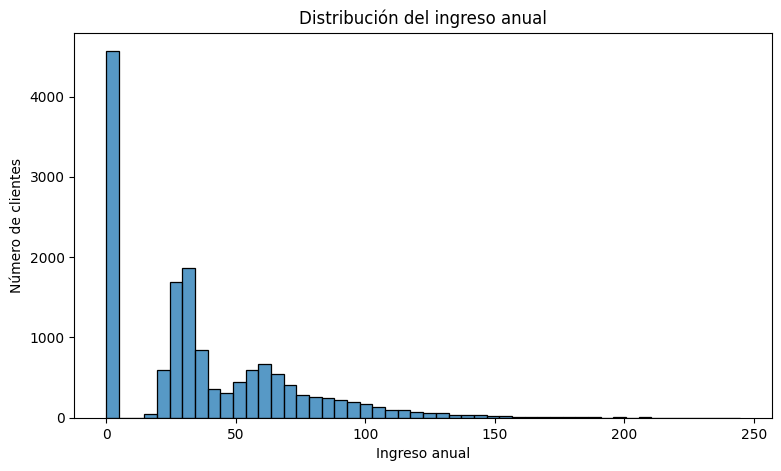

In [8]:
# Distribución de la variable foco: ingreso_anual
print("Proporción de clientes con ingreso 0:",
      round((df["ingreso_anual"] == 0).mean(), 3))

plt.figure(figsize=(9, 5))
sns.histplot(df["ingreso_anual"], bins=50)
plt.title("Distribución del ingreso anual")
plt.xlabel("Ingreso anual")
plt.ylabel("Número de clientes")
plt.show()

**Distribución de `ingreso_anual`**

- El 30.4 % de los clientes no generó ingreso durante el período (ingreso = 0).
- La distribución es asimétrica a la derecha y presenta picos separados alrededor de 30 y 60, lo que sugiere que el ingreso se acumula por número de compras.
- Debido a la concentración de ceros y a la falta de normalidad, se complementa Pearson con Spearman, que no requiere distribución normal.

### Diagnóstico de variables numéricas

El análisis descriptivo muestra que las variables numéricas contienen 15,000 registros y no presentan valores nulos.

- **Edad:** Los clientes tienen entre 18 y 75 años, con una edad promedio de 38.26 años.
- **Nivel de ingreso:** El ingreso estimado promedio es de 30,019.70, con valores entre 8,000 y 74,790.84, lo que refleja diferencias económicas entre clientes.
- **Visitas mensuales:** Los clientes realizan un promedio de 10.03 visitas al mes, con un mínimo de 1 y un máximo de 25.
- **Compras mensuales:** El promedio es de 1.21 compras por cliente, con valores entre 0 y 8. La mediana de 1 indica que al menos la mitad de los clientes realiza una compra o menos al mes.
- **Gasto en publicidad dirigida:** El promedio es de 20.15, con valores entre 0 y 75.51, mostrando diferencias en la inversión publicitaria asignada.
- **Satisfacción:** La calificación promedio es de 3.60 sobre 5, con valores entre 1 y 5.
- **Ingreso anual:** El promedio es de 36.59, con valores entre 0 y 244.69. La mediana (30.71) es menor que la media, y el 30.4 % de los clientes presenta ingreso 0, lo que indica una distribución asimétrica a la derecha.

**Conclusión:** Las variables presentan diferentes niveles de dispersión y rangos de valores. Será importante analizar sus relaciones con `ingreso_anual` mediante técnicas de correlación, sin asumir causalidad.

#### Explorar variables binarias

In [9]:
# Verificar que cada columna tenga únicamente dos valores posibles
print(df["miembro_premium"].unique())
print(df["abandono"].unique())

[0 1]
[0 1]


### Diagnóstico inicial de variables binarias

- `miembro_premium`: Presenta únicamente los valores 0 y 1, que permiten identificar si un cliente tiene membresía premium. No requiere transformación.
- `abandono`: Presenta únicamente los valores 0 y 1, que permiten identificar si un cliente abandonó la plataforma. No requiere transformación.

**Conclusión:** Ambas variables están correctamente codificadas y pueden utilizarse en el análisis de correlación.

#### Explorar variables categóricas

In [10]:
# Verificar el número de valores únicos por variable categórica
print(df["tipo_dispositivo"].nunique())
print(df["region"].nunique())

3
4


In [11]:
# Explorar variables categóricas y cómo se distribuyen
print(df["tipo_dispositivo"].value_counts())
print(df["region"].value_counts())

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64


### Diagnóstico inicial de variables categóricas

- **`tipo_dispositivo`:** Presenta 3 categorías: móvil (9,818 clientes), escritorio (3,720) y tablet (1,462). El dispositivo móvil es el más utilizado, representando aproximadamente el 65.45% de los clientes.

- **`region`:** Presenta 4 categorías: norte (4,395 clientes), oeste (3,810), sur (3,726) y este (3,069). La región norte concentra la mayor cantidad de clientes (29.30%).

**Conclusión:** Las variables categóricas presentan valores consistentes. Existe un predominio del dispositivo móvil, mientras que la distribución regional es más equilibrada. Ambas variables pueden utilizarse para analizar diferencias de comportamiento entre segmentos de clientes.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

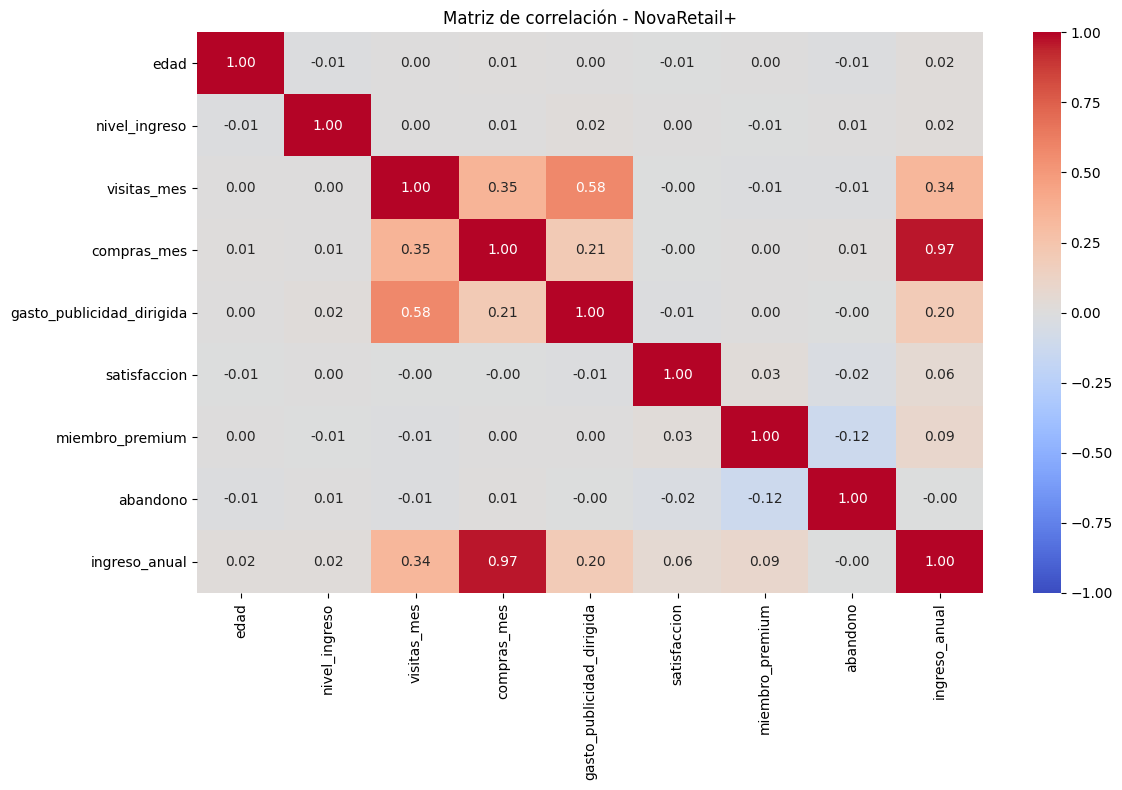

In [12]:
# Visualizar la matriz de correlación para identificar relaciones

# Seleccionar variables numéricas
df_numericas = df.select_dtypes(include="number")

# Calcular la matriz de correlación
matriz_corr = df_numericas.corr(method="pearson")

# Visualizar el Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de correlación - NovaRetail+")
plt.tight_layout()
plt.show()

### Observaciones generales (Heatmap)

- La relación positiva más fuerte se presenta entre `compras_mes` e `ingreso_anual` (r = 0.97).
- Se observa una correlación positiva moderada entre `visitas_mes` y `gasto_publicidad_dirigida` (r = 0.58).
- Las variables `visitas_mes` y `compras_mes` presentan una correlación positiva de 0.35.
- La relación entre `miembro_premium` y `abandono` es negativa y débil (r = -0.12).
- La mayoría de las demás correlaciones son cercanas a cero, lo que indica poca relación lineal.

### Observaciones respecto a `ingreso_anual`

- `compras_mes` presenta la correlación positiva más alta con `ingreso_anual` (r = 0.97).
- `visitas_mes` muestra una relación positiva moderada (r = 0.34).
- `gasto_publicidad_dirigida` presenta una relación positiva débil (r = 0.20).
- `edad` y `nivel_ingreso` presentan correlaciones muy cercanas a cero (r = 0.02).
- `abandono` prácticamente no presenta correlación lineal con `ingreso_anual` (r ≈ 0.00).

**Conclusión:** La cantidad de compras mensuales es la variable más estrechamente asociada con el ingreso anual dentro de esta matriz; sin embargo, esta relación se analiza con mayor detalle en la siguiente sección, ya que podría reflejar la forma en que se construye el ingreso. Estas relaciones son estadísticas y no implican causalidad.


### Scatterplot general

**Decisión: No incluir un scatterplot general.**

El Heatmap permitió identificar las principales relaciones entre las variables numéricas. Un scatterplot general produciría numerosas combinaciones, incluyendo relaciones cercanas a cero y variables binarias, lo que dificultaría su interpretación.

Por esta razón, se priorizarán scatterplots de pares clave para analizar con mayor detalle las relaciones más relevantes, su dispersión y posibles valores atípicos.

### Scatterplot para pares clave

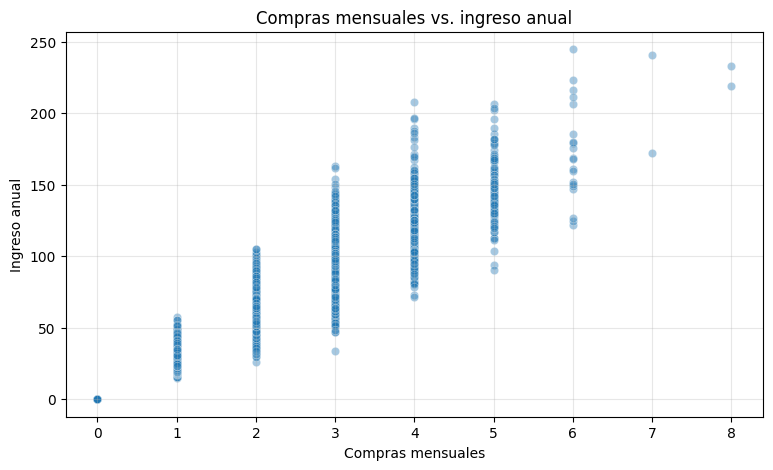

In [13]:
# Visualizar pares de variables con relaciones moderadas o fuertes
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="compras_mes",
    y="ingreso_anual",
    alpha=0.4
)

plt.title("Compras mensuales vs. ingreso anual")
plt.xlabel("Compras mensuales")
plt.ylabel("Ingreso anual")
plt.grid(alpha=0.3)
plt.show()

In [14]:
# Verificar si la relación compras-ingreso es "por construcción"
print("Ingreso de clientes sin compras:")
print(df.loc[df["compras_mes"] == 0, "ingreso_anual"].describe())

compradores = df[df["compras_mes"] > 0]
ticket = compradores["ingreso_anual"] / compradores["compras_mes"]

print("\nIngreso por compra (clientes con compras):")
print(ticket.describe())

Ingreso de clientes sin compras:
count    4567.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: ingreso_anual, dtype: float64

Ingreso por compra (clientes con compras):
count    10433.000000
mean        30.378201
std          5.336164
min         11.203333
25%         26.780000
50%         30.070000
75%         33.470000
max         57.290000
dtype: float64


**Diagnóstico del scatterplot: `compras_mes` vs. `ingreso_anual`**

Se observa una relación positiva muy fuerte (r = 0.97). Los puntos se distribuyen en columnas verticales porque `compras_mes` es una variable discreta.

**Verificación de la relación:**

- Los 4,567 clientes sin compras (30.4 %) presentan ingreso exactamente igual a 0.
- Entre los clientes con compras, el ingreso por compra es estable: promedio de 30.38, mediana de 30.07 y el 50 % central entre 26.78 y 33.47.

**Interpretación (correlación engañosa):** el ingreso anual se genera prácticamente como número de compras × ticket por compra (≈ 30). Por ello, la correlación de 0.97 es esperable por la forma en que se construye el ingreso y no constituye por sí misma un hallazgo sobre el comportamiento del cliente.

La pregunta de negocio relevante pasa a ser: **¿qué factores se asocian con que un cliente realice más compras?**


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [15]:
# Calcular correlación entre variables relevantes
# Correlación de Pearson
pearson_compras = df["compras_mes"].corr(
    df["ingreso_anual"],
    method="pearson"
)

print("Pearson compras vs ingreso anual:", round(pearson_compras, 2))

Pearson compras vs ingreso anual: 0.97


In [16]:
# Calcular correlación entre variables relevantes
# Correlación de Spearman
spearman_compras = df["compras_mes"].corr(
    df["ingreso_anual"],
    method="spearman"
)

print("Spearman compras vs ingreso anual:", round(spearman_compras, 2))
pearson_visitas = df["visitas_mes"].corr(
    df["gasto_publicidad_dirigida"],
    method="pearson"
)

spearman_visitas = df["visitas_mes"].corr(
    df["gasto_publicidad_dirigida"],
    method="spearman"
)

print("Pearson visitas vs publicidad:", round(pearson_visitas, 2))
print("Spearman visitas vs publicidad:", round(spearman_visitas, 2))

Spearman compras vs ingreso anual: 0.97
Pearson visitas vs publicidad: 0.58
Spearman visitas vs publicidad: 0.56



### Observaciones de correlación

**1. `compras_mes` vs. `ingreso_anual`**

- **Pearson = 0.97:** correlación lineal positiva muy fuerte.
- **Spearman = 0.97:** asociación monotónica positiva muy fuerte.
- **Dirección:** positiva. A mayor número de compras mensuales, mayor tiende a ser el ingreso anual.
- **Magnitud:** ambos coeficientes muestran una relación muy fuerte y consistente.
- **Nota:** como se verificó en la Sección 3, esta correlación refleja principalmente la forma en que se construye el ingreso (compras × ticket ≈ 30), por lo que no debe interpretarse como un hallazgo de comportamiento.

**2. `visitas_mes` vs. `gasto_publicidad_dirigida`**

- **Pearson = 0.58:** correlación lineal positiva moderada.
- **Spearman = 0.56:** asociación monotónica positiva moderada.
- **Dirección:** positiva. Los clientes con mayor número de visitas mensuales tienden a registrar mayor gasto en publicidad dirigida.
- **Magnitud:** ambos coeficientes son similares y muestran una asociación moderada.
- **Posible colinealidad:** ambas variables podrían utilizarse como predictoras del ingreso. Su correlación moderada (0.58) no constituye por sí sola multicolinealidad problemática, pero conviene tenerla en cuenta si se incluyen juntas en un modelo.
 
**Conclusión general**

Los resultados de Pearson y Spearman son consistentes para ambos pares. La relación más fuerte corresponde a `compras_mes` e `ingreso_anual`, aunque, como se verificó, se explica en gran medida por la construcción del ingreso. Por su parte, `visitas_mes` y `gasto_publicidad_dirigida` presentan una asociación moderada.

Estas correlaciones permiten identificar patrones estadísticos, pero no demuestran relaciones causales.

### Punto-biserial

In [17]:
# Calcular correlación entre variables relevantes
# Correlación punto-biserial: variables binarias vs variables numéricas

# Par 1: abandono vs satisfacción
r1, p1 = pointbiserialr(df["abandono"], df["satisfaccion"])

# Par 2: miembro premium vs ingreso anual
r2, p2 = pointbiserialr(df["miembro_premium"], df["ingreso_anual"])

# Par 3: abandono vs ingreso anual
r3, p3 = pointbiserialr(df["abandono"], df["ingreso_anual"])

print(f"Abandono vs satisfacción:  r = {r1:.3f}, p = {p1:.4f}")
print(f"Premium vs ingreso anual:  r = {r2:.3f}, p = {p2:.4f}")
print(f"Abandono vs ingreso anual: r = {r3:.3f}, p = {p3:.4f}")

Abandono vs satisfacción:  r = -0.024, p = 0.0035
Premium vs ingreso anual:  r = 0.093, p = 0.0000
Abandono vs ingreso anual: r = -0.003, p = 0.7295


### Observaciones de correlación punto-biserial

**1. `abandono` vs. `satisfaccion`** (r = -0.024, p = 0.0035)

- **Dirección:** negativa; mayor satisfacción se asocia mínimamente con menor abandono.
- **Magnitud:** prácticamente nula (r² ≈ 0.0006).
- **Interpretación:** aunque el resultado es estadísticamente significativo, su magnitud es irrelevante en la práctica. Con 15,000 registros, incluso asociaciones mínimas alcanzan significancia.

**2. `miembro_premium` vs. `ingreso_anual`** (r = 0.093, p < 0.001)

- **Dirección:** positiva; los miembros premium presentan, en promedio, un ingreso ligeramente mayor.
- **Magnitud:** muy débil.
- **Interpretación:** la asociación es significativa, pero la membresía premium por sí sola explica muy poco de las diferencias de ingreso entre clientes.

**3. `abandono` vs. `ingreso_anual`** (r = -0.003, p = 0.7295)

- **Dirección y magnitud:** sin asociación.
- **Interpretación:** no hay evidencia de que el ingreso generado difiera entre clientes que abandonaron y los que permanecieron. El abandono no se concentra en clientes de bajo valor, lo cual es relevante para las estrategias de retención.

**Conclusión general**

Las tres correlaciones punto-biseriales son débiles o nulas. Los resultados muestran que la significancia estadística (p-value) no equivale a relevancia práctica: con muestras grandes, es necesario evaluar también la magnitud del coeficiente. Estas asociaciones no permiten establecer relaciones causales.

### V de Cramér

In [18]:
# Función para calcular V de Cramér

def cramers_v(variable1, variable2):
    tabla = pd.crosstab(variable1, variable2)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    filas, columnas = tabla.shape

    return np.sqrt(chi2 / (n * min(filas - 1, columnas - 1)))

In [19]:
# Aplicar V de Cramér en variables relevantes
v_dispositivo_abandono = cramers_v(
    df["tipo_dispositivo"],
    df["abandono"]
)

v_region_premium = cramers_v(
    df["region"],
    df["miembro_premium"]
)

print("V de Cramér dispositivo vs abandono:",
      round(v_dispositivo_abandono, 3))

print("V de Cramér región vs premium:",
      round(v_region_premium, 3))


V de Cramér dispositivo vs abandono: 0.007
V de Cramér región vs premium: 0.013


In [20]:
# Ingreso anual por segmento categórico
print("Ingreso anual por región:")
print(df.groupby("region")["ingreso_anual"].agg(["mean", "median", "count"]).round(2))

print("\nIngreso anual por tipo de dispositivo:")
print(df.groupby("tipo_dispositivo")["ingreso_anual"].agg(["mean", "median", "count"]).round(2))

Ingreso anual por región:
         mean  median  count
region                      
este    36.89   30.78   3069
norte   36.71   30.72   4395
oeste   35.72   30.36   3810
sur     37.10   30.94   3726

Ingreso anual por tipo de dispositivo:
                   mean  median  count
tipo_dispositivo                      
escritorio        36.42   30.44   3720
móvil             36.59   30.69   9818
tablet            37.07   31.34   1462


### Observaciones de V de Cramér

**1. `tipo_dispositivo` vs. `abandono`**

- **V de Cramér = 0.007:** asociación prácticamente nula.
- **Magnitud:** el coeficiente está muy próximo a cero, lo que indica una asociación extremadamente débil entre ambas variables.
- **Interpretación:** no se observa una asociación relevante entre el tipo de dispositivo utilizado y el abandono de los clientes. En este conjunto de datos, conocer el dispositivo aporta muy poca información sobre el abandono.

**2. `region` vs. `miembro_premium`**

- **V de Cramér = 0.013:** asociación prácticamente nula.
- **Magnitud:** el coeficiente es muy cercano a cero, lo que refleja una asociación extremadamente débil.
- **Interpretación:** no se identifica una asociación relevante entre la región del cliente y su pertenencia al programa premium.
  
**3. `ingreso_anual` por `region` y `tipo_dispositivo`**

Como V de Cramér solo aplica entre variables categóricas, se comparó directamente el ingreso anual por segmento:

- **Región:** medias entre 35.72 (oeste) y 37.10 (sur); medianas entre 30.36 y 30.94.
- **Dispositivo:** medias entre 36.42 (escritorio) y 37.07 (tablet); medianas entre 30.44 y 31.34.
- **Interpretación:** las diferencias son mínimas (≈ 1 punto) frente a la variabilidad del ingreso (desviación estándar ≈ 34.5). No se observa asociación relevante entre la región o el dispositivo y el ingreso generado.

**Conclusión general**

Los coeficientes de V de Cramér son extremadamente bajos y la comparación de ingresos por segmento muestra diferencias mínimas. Ni la región ni el tipo de dispositivo presentan asociaciones relevantes con el abandono, la membresía premium o el ingreso anual.

V de Cramér mide la intensidad de la asociación, pero no indica dirección. Estos resultados no demuestran independencia estadística absoluta ni relaciones causales.

### Verificación de correlación engañosa: publicidad dirigida e ingreso

In [21]:
# ¿La relación publicidad-ingreso se mantiene entre clientes con visitas similares?
print("Correlación global publicidad vs ingreso:",
      round(df["gasto_publicidad_dirigida"].corr(df["ingreso_anual"]), 3))

df["grupo_visitas"] = pd.qcut(df["visitas_mes"], q=4, duplicates="drop")

print("\nCorrelación publicidad vs ingreso dentro de cada grupo de visitas:")
print(
    df.groupby("grupo_visitas")
      .apply(lambda g: g["gasto_publicidad_dirigida"].corr(g["ingreso_anual"]))
      .round(3)
)
# Eliminar la columna auxiliar
df = df.drop(columns="grupo_visitas")

Correlación global publicidad vs ingreso: 0.197

Correlación publicidad vs ingreso dentro de cada grupo de visitas:
grupo_visitas
(0.999, 8.0]    0.066
(8.0, 10.0]     0.004
(10.0, 12.0]    0.016
(12.0, 25.0]    0.045
dtype: float64


**Resultado de la verificación**

- Correlación global entre `gasto_publicidad_dirigida` e `ingreso_anual`: r = 0.197.
- Dentro de grupos de clientes con número similar de visitas, la correlación cae a valores entre 0.004 y 0.066, prácticamente nulos.

**Interpretación (correlación engañosa):** la asociación global entre publicidad e ingreso se explica en gran medida por las visitas mensuales. La publicidad dirigida tiende a asignarse a clientes con más visitas (r = 0.58), y estos clientes también generan más ingreso. Las visitas actúan como variable de confusión.

**No podemos afirmar** que aumentar el gasto en publicidad dirigida incremente el ingreso. Para evaluar su efecto real se requeriría un experimento controlado (por ejemplo, un A/B test).

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo se presenta con evidencia visual, evidencia numérica, una interpretación no causal, lo que no podemos afirmar y su implicación para el negocio.

### Hallazgo 1 — El ingreso anual depende casi por completo del número de compras

**1. Evidencia visual**

El scatterplot muestra columnas verticales con una tendencia ascendente marcada, y el histograma de `ingreso_anual` presenta picos alrededor de 0, 30 y 60, que corresponden a 0, 1 y 2 compras.

**2. Evidencia numérica**

- Pearson = 0.97 y Spearman = 0.97.
- Los 4,567 clientes sin compras (30.4 %) tienen ingreso exactamente igual a 0.
- El ingreso por compra es estable: promedio de 30.38, mediana de 30.07 y el 50 % central entre 26.78 y 33.47.

**3. Interpretación (no causal)**

El ingreso anual se comporta prácticamente como número de compras × ticket por compra (≈ 30). La correlación de 0.97 refleja la forma en que se genera el ingreso más que un patrón de comportamiento del cliente. Se trata de una correlación esperable que puede resultar engañosa si se presenta como hallazgo.

**4. No podemos afirmar**

No podemos afirmar qué factores llevan a un cliente a comprar más. La correlación describe la composición del ingreso, no sus determinantes.

**5. Implicación de negocio**

- El crecimiento del ingreso depende de dos palancas: **aumentar la frecuencia de compra** y **activar al 30.4 % de clientes que no compraron**.
- El ticket por compra es relativamente estable, por lo que hay menos margen de crecimiento por esa vía sin estrategias específicas (por ejemplo, venta cruzada).
- Los análisis futuros deberían usar `compras_mes` como variable objetivo para identificar qué comportamientos se asocian con mayor frecuencia de compra.

### Hallazgo 2 — Las visitas se asocian con el ingreso; la publicidad dirigida no, una vez consideradas las visitas

**1. Evidencia visual**

El heatmap muestra que `visitas_mes` tiene una asociación positiva moderada con `ingreso_anual` (r = 0.34) y con `gasto_publicidad_dirigida` (r = 0.58), mientras que la publicidad presenta una asociación débil con el ingreso (r = 0.20).

**2. Evidencia numérica**

- `visitas_mes` vs `gasto_publicidad_dirigida`: Pearson = 0.58, Spearman = 0.56.
- `gasto_publicidad_dirigida` vs `ingreso_anual`: r = 0.197 global.
- Dentro de grupos de clientes con visitas similares, la correlación entre publicidad e ingreso cae a valores entre 0.004 y 0.066.

**3. Interpretación (no causal)**

Los clientes que visitan más la plataforma tienden a generar más ingreso. La asociación aparente entre publicidad e ingreso se explica en gran medida por las visitas: la publicidad dirigida se asigna con mayor frecuencia a clientes activos, que ya generan más ingreso. Las visitas actúan como variable de confusión.

**4. No podemos afirmar**

- Que aumentar la inversión en publicidad dirigida incremente el ingreso.
- Que más visitas provoquen más compras; ambas podrían reflejar un mayor interés previo del cliente.

**5. Implicación de negocio**

- Antes de aumentar el presupuesto de publicidad dirigida, conviene evaluar su efecto real mediante un experimento controlado (A/B test).
- La frecuencia de visitas puede usarse como indicador temprano de clientes con mayor potencial de compra.

### Hallazgo 3 — Los segmentos y características del cliente muestran asociaciones débiles o nulas con el ingreso

**1. Evidencia visual**

En el heatmap, `edad` y `nivel_ingreso` presentan correlaciones cercanas a cero con `ingreso_anual` (r = 0.02).

**2. Evidencia numérica**

- `miembro_premium` vs `ingreso_anual`: r = 0.093 (p < 0.001), significativa pero muy débil.
- `abandono` vs `ingreso_anual`: r = -0.003 (p = 0.7295), sin asociación.
- Ingreso por región: medias entre 35.72 y 37.10.
- Ingreso por dispositivo: medias entre 36.42 y 37.07.

**3. Interpretación (no causal)**

Las características demográficas y de segmento del cliente (edad, nivel de ingreso personal, región, dispositivo) prácticamente no se asocian con el ingreso generado. La membresía premium presenta una asociación positiva muy pequeña. Los clientes que abandonaron habían generado un ingreso similar al de quienes permanecieron.

**4. No podemos afirmar**

- Que la membresía premium aumente el ingreso de los clientes.
- Que el abandono no tenga impacto económico: perder un cliente implica perder sus compras futuras, aunque su ingreso pasado fuera promedio.

**5. Implicación de negocio**

- Segmentar campañas por región, dispositivo, edad o nivel de ingreso personal no parece útil para identificar clientes de mayor valor; el comportamiento (compras y visitas) es más informativo.
- Las estrategias de retención no deberían enfocarse solo en clientes de bajo valor, ya que el abandono ocurre en todos los niveles de ingreso.
- Conviene revisar la propuesta de valor del programa premium, dado que su asociación con el ingreso es mínima.

## Sección 6 - Limitaciones y próximos pasos

### Limitaciones

**1. Correlación no implica causalidad**

Las asociaciones identificadas describen relaciones estadísticas. No permiten afirmar que una variable provoque cambios en otra.

**2. Relación por construcción entre compras e ingreso**

El ingreso anual se comporta prácticamente como número de compras × ticket (≈ 30). Por ello, la correlación de 0.97 describe la composición del ingreso y no explica qué factores llevan a un cliente a comprar más.

**3. Variables de confusión**

La asociación entre publicidad dirigida e ingreso desaparece al comparar clientes con visitas similares. Pueden existir otras variables de confusión no identificadas en este análisis.

**4. Significancia frente a relevancia práctica**

Con 15,000 registros, incluso correlaciones mínimas resultan estadísticamente significativas (por ejemplo, abandono vs satisfacción: r = -0.024, p = 0.0035). La interpretación se basó en la magnitud de los coeficientes y no solo en los p-values.

**5. Variables no disponibles**

El dataset no incluye información sobre promociones, precios, categorías de producto, estacionalidad ni historial de compras, factores que podrían explicar parte del comportamiento del cliente.

**6. Alcance temporal y definición de variables**

El análisis corresponde únicamente a 2024. Además, el enunciado menciona `ingresos_mensuales` como métrica foco, mientras que el dataset contiene `ingreso_anual`; se asumió que esta última representa el valor generado por cada cliente en el período.

### Próximos pasos

**1. Analizar los factores asociados con la frecuencia de compra**

- Usar `compras_mes` como variable objetivo para identificar qué comportamientos se asocian con comprar más.
- Analizar por separado al 30.4 % de clientes sin compras para entender qué los diferencia de los compradores.

**2. Evaluar el efecto real de la publicidad dirigida**

- Diseñar un experimento controlado (A/B test) que compare clientes con y sin publicidad dirigida y un número similar de visitas.

**3. Revisar el programa premium y la retención**

- Evaluar qué beneficios ofrece la membresía premium, dado que su asociación con el ingreso es mínima.
- Investigar las causas del abandono con variables adicionales, ya que no se asocia con el ingreso, la satisfacción, la región ni el dispositivo.

**4. Ampliar el análisis**

- Incorporar datos de otros períodos para validar si los patrones se mantienen.
- Explorar modelos multivariables que controlen varias variables al mismo tiempo.

## Reporte ejecutivo

**Pregunta de negocio:** ¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado en NovaRetail+ durante 2024?

**Alcance:** análisis correlacional de 15,000 clientes, sin valores nulos ni duplicados. Los resultados describen asociaciones, no relaciones causales.

### Hallazgos principales

1. **El ingreso depende casi por completo del número de compras.** La correlación es de 0.97, pero se explica por la forma en que se genera el ingreso: cada compra aporta en promedio ≈ 30. El **30.4 % de los clientes no realizó compras** y generó ingreso 0.

2. **Las visitas se asocian con el ingreso; la publicidad dirigida no.** Las visitas presentan una asociación moderada con el ingreso (r = 0.34). La publicidad muestra una asociación aparente (r = 0.20) que desaparece al comparar clientes con visitas similares (r entre 0.004 y 0.066), por lo que se trata de una correlación engañosa.

3. **El perfil del cliente aporta poca información sobre su valor.** Edad, nivel de ingreso personal, región y dispositivo no se asocian con el ingreso. La membresía premium muestra una asociación muy débil (r = 0.093), y el abandono ocurre en todos los niveles de ingreso (r = -0.003).

### Recomendaciones

- **Activar a los clientes sin compras:** representan casi un tercio de la base y son la mayor oportunidad de crecimiento.
- **Usar la frecuencia de visitas** como indicador temprano de clientes con potencial de compra.
- **Validar la publicidad dirigida con un A/B test** antes de aumentar su presupuesto.
- **Revisar la propuesta de valor del programa premium** y las estrategias de retención, que no deberían limitarse a clientes de bajo valor.

### Limitaciones

El análisis es correlacional y corresponde solo a 2024. No incluye variables como precios, promociones o categorías de producto. Con muestras grandes, correlaciones mínimas resultan significativas, por lo que las conclusiones se basan en la magnitud de los coeficientes.

### Próximo paso recomendado

Analizar qué comportamientos se asocian con una **mayor frecuencia de compra**, usando `compras_mes` como variable objetivo y comparando a compradores con no compradores.